# B01 — Política de riesgo de tipos y mix fijo-variable

**Objetivos:** generar escenarios de Euribor coherentes con la curva; medir el riesgo del coste financiero
(ICaR); construir la frontera eficiente coste-riesgo de mixes fijo-variable y plazos; caso del grupo de
telecomunicaciones.

**Fuentes:** Myint cap. 1, 8, 9 y 10; Gatto cap. 8–9. Datos sintéticos.

El modelo de escenarios es un Hull-White de un factor ajustado a la curva de hoy. Aquí se usa como
herramienta: se explica en C3.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent          # notebooks/ -> repository root
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True

from derivlab.market import sample_market
from derivlab.curves import build_curves
from derivlab.scenarios import HullWhite
from derivlab.hedging import simulate_fixings, frontier, icar, mix_cost, term_premium

m = sample_market()
estr, eur = build_curves(m)
hw = HullWhite(estr, eur, a=0.03, sigma=0.0085)
H, N_PATHS = 5, 20000
print(f"Model: a = {hw.a}, sigma = {hw.sigma:.2%} (normal, per year)")

Model: a = 0.03, sigma = 0.85% (normal, per year)


## 1. Escenarios de Euribor 6M a 5 años

Dos juegos de escenarios con los mismos choques:

- **Neutral al riesgo:** centrados en los forwards. Es el mundo en que se valoran los derivados.
- **Mundo real (supuesto):** forwards menos una prima por plazo $tp(t) = 0{,}60\,\% \cdot (1 - e^{-t/3})$.
  Recoge la idea de Myint (cap. 10) de que los forwards tienden a sobrestimar los tipos realizados.

t         0.0   1.0   2.0   3.0   4.0
forward  2.04  2.13  2.40  2.58  2.74
p5       2.04  0.59  0.21 -0.09 -0.32
median   2.04  1.96  2.10  2.19  2.29
p95      2.04  3.34  4.02  4.50  4.95


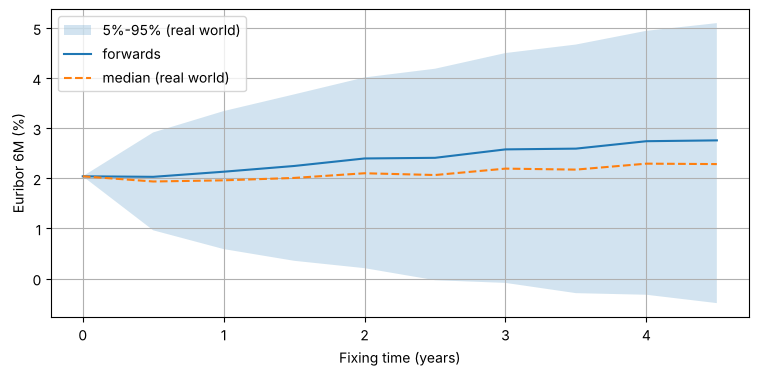

CASE Euribor 6M fixing in 4.5y: forward 2.76%, real-world 5%-95% -0.49% to 5.10%


In [2]:
TP_MAX = 0.0060
times, fix_q = simulate_fixings(hw, H, N_PATHS, seed=7, tp_max=0.0)
_, fix_p = simulate_fixings(hw, H, N_PATHS, seed=7, tp_max=TP_MAX)
fan = pd.DataFrame({"t": times, "forward": fix_q.mean(axis=0),
                    "p5": np.quantile(fix_p, 0.05, axis=0), "median": np.median(fix_p, axis=0),
                    "p95": np.quantile(fix_p, 0.95, axis=0)})
print((fan.set_index("t") * 100).round(2).T.iloc[:, ::2])
plt.fill_between(fan.t, fan.p5 * 100, fan.p95 * 100, alpha=0.2, label="5%-95% (real world)")
plt.plot(fan.t, fan.forward * 100, label="forwards")
plt.plot(fan.t, fan["median"] * 100, "--", label="median (real world)")
plt.xlabel("Fixing time (years)"); plt.ylabel("Euribor 6M (%)"); plt.legend(); plt.show()
print(f"CASE Euribor 6M fixing in 4.5y: forward {fan.forward.iloc[-1]:.2%}, real-world 5%-95% "
      f"{fan.p5.iloc[-1]:.2%} to {fan.p95.iloc[-1]:.2%}")

## 2. Caso: el mix fijo-variable de un grupo de telecomunicaciones

**Telco Ibérica** (ficticia, *investment grade*) tiene 3.000 M€ de deuda a Euribor 6M + 1,20 % de margen y un
EBITDA de 1.500 M€. Su política actual fija el 70 % con swaps a 5 años. El comité de riesgos quiere saber si esa
política es eficiente para su horizonte de plan de negocio (5 años).

Para cada combinación de proporción fija (0 % a 100 %) y plazo del swap (1 a 5 años) se calcula, sobre los
escenarios del mundo real, el **coste medio anual** a 5 años y su **ICaR al 95 %** (percentil 95 menos la media).
Si el swap vence antes del horizonte, esa parte vuelve a pagar Euribor.

In [3]:
DEBT, MARGIN, EBITDA = 3000.0, 0.0120, 1500.0
tenors = [1, 2, 3, 4, 5]
swap_rates = {k: float(hw.swap_rate(0.0, np.zeros(1), k)[0][0]) for k in tenors}
print("Par swap rates today (annual fixed vs 6M):", {k: f"{v:.3%}" for k, v in swap_rates.items()})
shares = np.round(np.arange(0, 1.01, 0.1), 2)
fr = frontier(fix_p, swap_rates, shares, tenors, H)
current = fr[(fr.fixed_share == 0.7) & (fr.swap_years == 5)].iloc[0]
eff = fr[fr.efficient].sort_values("icar")
print(f"CASE current policy (70% fixed, 5y): expected cost {current.expected_cost:.3%} + margin, "
      f"ICaR95 {current.icar:.3%} = {current.icar * DEBT:.1f} M EUR per year")
show = eff[["fixed_share", "swap_years", "expected_cost", "icar"]].copy()
show["icar_meur"] = show.icar * DEBT
print(show.to_string(index=False, formatters={"expected_cost": "{:.3%}".format, "icar": "{:.3%}".format,
                                              "icar_meur": "{:.1f}".format, "fixed_share": "{:.0%}".format}))

Par swap rates today (annual fixed vs 6M): {1: '2.073%', 2: '2.147%', 3: '2.238%', 4: '2.323%', 5: '2.402%'}


CASE current policy (70% fixed, 5y): expected cost 2.314% + margin, ICaR95 0.477% = 14.3 M EUR per year
fixed_share  swap_years expected_cost   icar icar_meur
       100%           5        2.402% 0.000%       0.0
        90%           5        2.372% 0.159%       4.8
        80%           5        2.343% 0.318%       9.5
        70%           5        2.314% 0.477%      14.3
        90%           4        2.297% 0.627%      18.8
        60%           5        2.285% 0.636%      19.1
        80%           4        2.276% 0.730%      21.9
        50%           5        2.256% 0.795%      23.9
        70%           4        2.256% 0.836%      25.1
        60%           4        2.235% 0.943%      28.3
        40%           5        2.227% 0.954%      28.6
        50%           4        2.214% 1.049%      31.5
        80%           3        2.214% 1.090%      32.7
        30%           5        2.198% 1.113%      33.4
        40%           4        2.193% 1.155%      34.7
        60%     

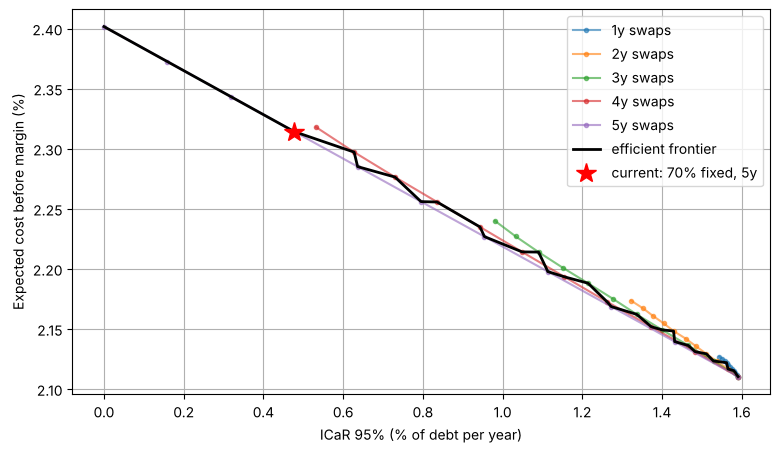

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
for k in tenors:
    s = fr[fr.swap_years == k]
    ax.plot(s.icar * 100, s.expected_cost * 100, "o-", ms=3, alpha=0.6, label=f"{k}y swaps")
ax.plot(eff.icar * 100, eff.expected_cost * 100, "k-", lw=2, label="efficient frontier")
ax.plot(current.icar * 100, current.expected_cost * 100, "r*", ms=15, label="current: 70% fixed, 5y")
ax.set_xlabel("ICaR 95% (% of debt per year)"); ax.set_ylabel("Expected cost before margin (%)")
ax.legend(); plt.show()

### Propuesta

El comité acepta como máximo 25 M€ al año de ICaR (un 1,7 % del EBITDA, sin impacto en el rating). Se elige el
punto más barato que cumple ese límite y se compara con la política actual.

In [5]:
LIMIT = 25.0 / DEBT
ok = fr[fr.icar <= LIMIT].sort_values("expected_cost")
best = ok.iloc[0]
saving = (current.expected_cost - best.expected_cost) * DEBT
print(f"CASE proposal: {best.fixed_share:.0%} fixed with {int(best.swap_years)}y swaps; expected cost "
      f"{best.expected_cost:.3%}, ICaR {best.icar:.3%} ({best.icar * DEBT:.1f} M EUR)")
print(f"CASE expected saving vs current = {saving:.1f} M EUR per year, with ICaR "
      f"{current.icar * DEBT:.1f} -> {best.icar * DEBT:.1f} M EUR")

def interest_cover(share, years, q):
    c = mix_cost(fix_p, swap_rates, share, years, H) + MARGIN
    return EBITDA / (np.quantile(c, q) * DEBT)
print(f"CASE EBITDA/interest at the 95th percentile cost: current {interest_cover(0.7, 5, 0.95):.1f}x, "
      f"proposal {interest_cover(best.fixed_share, int(best.swap_years), 0.95):.1f}x, "
      f"all floating {interest_cover(0.0, 5, 0.95):.1f}x")

CASE proposal: 50% fixed with 5y swaps; expected cost 2.256%, ICaR 0.795% (23.9 M EUR)
CASE expected saving vs current = 1.7 M EUR per year, with ICaR 14.3 -> 23.9 M EUR
CASE EBITDA/interest at the 95th percentile cost: current 12.5x, proposal 11.8x, all floating 10.2x


## 3. ¿De dónde sale el ahorro? La prima del swap

Con escenarios neutrales al riesgo (centrados en los forwards), fijar no cuesta nada en media: el swap es un
seguro a precio justo. Todo el ahorro esperado de flotar procede del supuesto de prima por plazo.
La prima del swap a *n* años es el tipo del swap menos el Euribor medio realizado.

In [6]:
rows = []
for k in tenors:
    tk = int(k / 0.5)
    realised_p = fix_p[:, :tk].mean(axis=1)
    realised_q = fix_q[:, :tk].mean(axis=1)
    rows.append({"tenor": k, "swap_rate": swap_rates[k], "premium_real_world": swap_rates[k] - realised_p.mean(),
                 "premium_risk_neutral": swap_rates[k] - realised_q.mean(),
                 "prob_fixing_saves": (realised_p > swap_rates[k]).mean()})
prem = pd.DataFrame(rows)
print(prem.to_string(index=False, formatters={"swap_rate": "{:.3%}".format, "premium_real_world": "{:.3%}".format,
                                              "premium_risk_neutral": "{:.3%}".format,
                                              "prob_fixing_saves": "{:.0%}".format}))
print(f"CASE 5y swap premium: real world {prem.premium_real_world.iloc[-1]:.2%}, risk neutral "
      f"{prem.premium_risk_neutral.iloc[-1]:.2%}; Myint's historical EUR figure (1999-2013) was 1.44%")

 tenor swap_rate premium_real_world premium_risk_neutral prob_fixing_saves
     1    2.073%             0.083%               0.037%               39%
     2    2.147%             0.158%               0.034%               38%
     3    2.238%             0.216%               0.028%               38%
     4    2.323%             0.259%               0.019%               38%
     5    2.402%             0.291%               0.008%               38%
CASE 5y swap premium: real world 0.29%, risk neutral 0.01%; Myint's historical EUR figure (1999-2013) was 1.44%


## 4. Comprobaciones

In [7]:
full = fr[(fr.fixed_share == 1.0) & (fr.swap_years == 5)].iloc[0]
assert abs(full.icar) < 1e-12 and abs(full.expected_cost - swap_rates[5]) < 1e-12
assert fr[fr.fixed_share == 0.0].icar.iloc[0] > current.icar > 0
assert best.icar <= LIMIT and best.expected_cost <= current.expected_cost
assert abs(prem.premium_risk_neutral.iloc[-1]) < 0.0010      # forwards: fixing costs ~0 on average
assert (np.diff(prem.premium_real_world) > 0).all()
print("All checks passed")

All checks passed


## Ejercicios

1. **Básico.** ¿Cuánto vale el ICaR de dejar toda la deuda a tipo variable, en % y en M€ al año?
2. **Intermedio.** Repite el análisis sin prima por plazo (`TP_MAX = 0`). ¿Qué punto elige ahora el límite de ICaR y por qué?
3. **Avanzado.** Telco Ibérica tiene además 600 M€ de caja remunerada a €STR. Calcula el ICaR de la política actual sobre la deuda neta (la caja compensa parte del riesgo de la deuda variable, Myint cap. 9).

## Soluciones

In [8]:
z = fr[(fr.fixed_share == 0.0)].iloc[0]
print(f"All floating: ICaR {z.icar:.3%} = {z.icar * DEBT:.1f} M EUR per year")

All floating: ICaR 1.591% = 47.7 M EUR per year


In [9]:
fr0 = frontier(fix_q, swap_rates, shares, tenors, H)
b0 = fr0[fr0.icar <= LIMIT].sort_values("expected_cost").iloc[0]
print(f"Without term premium: {b0.fixed_share:.0%} fixed, {int(b0.swap_years)}y, cost {b0.expected_cost:.3%}, ICaR {b0.icar:.3%}")
print("Costs are now almost flat across strategies; the choice is driven by risk and by the curve slope only.")

Without term premium: 50% fixed, 5y, cost 2.397%, ICaR 0.795%
Costs are now almost flat across strategies; the choice is driven by risk and by the curve slope only.


In [10]:
CASH = 600.0
cash_rate = fix_p - 0.0016           # €STR is about 16 bp below Euribor 6M at the short end (A3)
def net_cost(share, years):
    gross = mix_cost(fix_p, swap_rates, share, years, H) * DEBT
    return gross - cash_rate.mean(axis=1) * CASH
nc = net_cost(0.7, 5)
print(f"Net interest cost at risk (current policy): {np.quantile(nc, 0.95) - nc.mean():.1f} M EUR "
      f"vs {current.icar * DEBT:.1f} M EUR on gross debt")

Net interest cost at risk (current policy): 4.8 M EUR vs 14.3 M EUR on gross debt
